# Figure 5

Redraws the panels of Fig. 5 from the source data.

The source data are deposited on figshare (https://doi.org/10.6084/m9.figshare.34601982): `Wilhelm_SourceData.xlsx` (one worksheet per panel), per-point `Wilhelm_SourceData_*.parquet` files and summary `Wilhelm_SourceData_*.csv` files; `README.md` of the deposit describes all columns. `source_data.py` downloads the files into `./data` on first use. Set `FIGSHARE_ARTICLE_ID` in the next cell (or as environment variable; `FIGSHARE_TOKEN` while the article is private), or point `SOURCE_DATA_DIR` to a local copy of the files.

* a, d, e: worksheets `Fig5a`, `Fig5d`, `Fig5e`
* b: `Wilhelm_SourceData_Fig5b.parquet` (spectral angle per spectrum) and `Wilhelm_SourceData_Fig5b_n.csv` (upset matrix, n and medians per combination)
* c: `Wilhelm_SourceData_Fig5c.parquet` (spectral angle per PSM) and `Wilhelm_SourceData_Fig5c_n.csv` (n and medians)


In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'Fig5'
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(name):
    for ext in ('pdf', 'png'):
        plt.savefig(FIG_DIR / f'{name}.{ext}', dpi=300, bbox_inches='tight')


readme('Fig5')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Fig. 5,a,Fig5a,NaN,PSMs gained with Prosit-22PTM rescoring per mo...,Fig5a
1,Fig. 5,b,NaN,Wilhelm_SourceData_Fig5b.parquet; Wilhelm_Sour...,Spectral angle of each spectrum per PTM combin...,NaN
2,Fig. 5,c,NaN,Wilhelm_SourceData_Fig5c.parquet; Wilhelm_Sour...,Spectral angle of each PSM (Prosit-22PTM resco...,NaN
3,Fig. 5,d,Fig5d,NaN,PSMs common / gained / lost with Prosit-22PTM ...,Fig5d
4,Fig. 5,e,Fig5e,NaN,Histone H3 modification states per sample prep...,Fig5e


## Panel a — PSMs gained with rescoring per modification-residue pair (HLA class I)

PSMs gained with Prosit-22PTM rescoring per modification-residue pair (HLA class I data sets PXD000394, PXD003790, PXD004894, PXD006939, PXD009738; PSM q-value <= 0.01 for MSFragger + Percolator and for Prosit-22PTM rescoring). Gain (%) = (rescoring - MSFragger) / MSFragger x 100, 100 % where MSFragger has no PSM; bars sorted by gain and coloured by category.

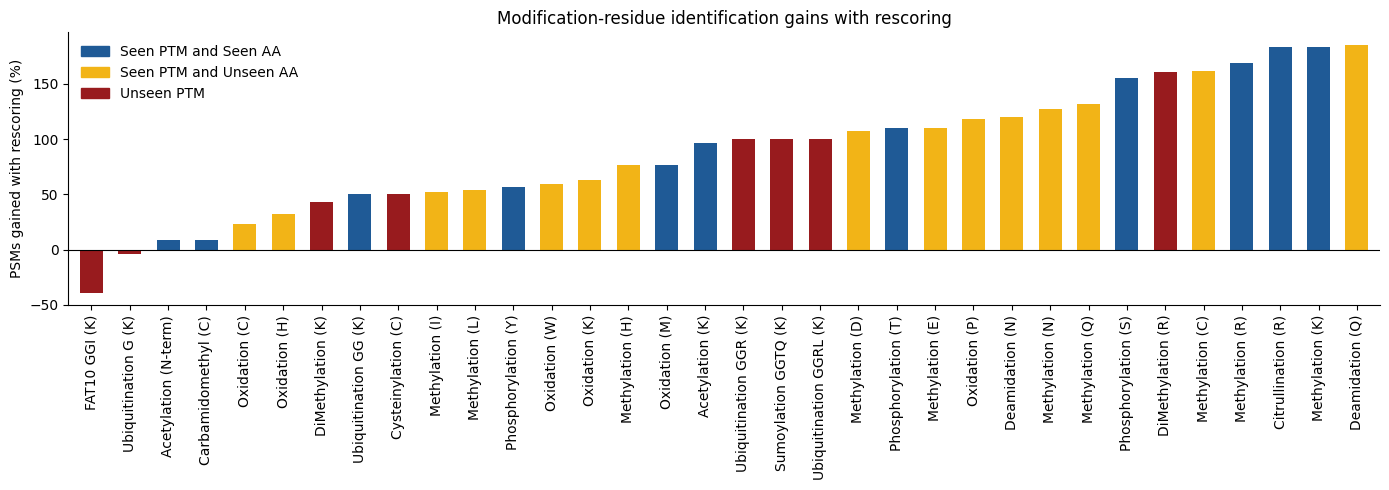

,modification (residue),unimod_token,category,n_PSMs_MSFragger_Percolator (q<=0.01),n_PSMs_Prosit-22PTM_rescoring (q<=0.01),PSMs_gained_with_rescoring (%; 100 if no MSFragger PSM)
0,FAT10 GGI (K),K[UNIMOD:19903],Unseen PTM,90,55,-38.888889
1,Ubiquitination G (K),K[UNIMOD:1263],Unseen PTM,92,88,-4.347826
2,Acetylation (N-term),[UNIMOD:1]-,Seen PTM and Seen AA,4121,4492,9.002669
3,Carbamidomethyl (C),C[UNIMOD:4],Seen PTM and Seen AA,17770,19373,9.020822
4,Oxidation (C),C[UNIMOD:35],Seen PTM and Unseen AA,504,620,23.015873
5,Oxidation (H),H[UNIMOD:35],Seen PTM and Unseen AA,2458,3249,32.180635
6,DiMethylation (K),K[UNIMOD:36],Unseen PTM,7,10,42.857143
7,Ubiquitination GG (K),K[UNIMOD:121],Seen PTM and Seen AA,28,42,50.000000
8,Cysteinylation (C),C[UNIMOD:312],Unseen PTM,157,236,50.318471
9,Methylation (I),I[UNIMOD:34],Seen PTM and Unseen AA,396,602,52.020202


In [3]:
a = table('Fig5a')
GAIN = 'PSMs_gained_with_rescoring (%; 100 if no MSFragger PSM)'
CAT_COL = {'Seen PTM and Seen AA': '#1f5a96', 'Seen PTM and Unseen AA': '#f2b417', 'Unseen PTM': '#981b1e'}
a = a.sort_values(GAIN, na_position='last', kind='stable').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(a))
ax.bar(x, a[GAIN].fillna(0), color=a['category'].map(CAT_COL), width=0.6)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(x, a['modification (residue)'], rotation=90)
ax.set_xlim(-0.6, len(a) - 0.4)
ax.set_ylabel('PSMs gained with rescoring (%)')
ax.set_title('Modification-residue identification gains with rescoring')
ax.legend([Patch(color=c) for c in CAT_COL.values()], CAT_COL.keys(), frameon=False, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
save('Fig5a')
plt.show()
a

## Panel b — Prosit-22PTM spectral angle across PTM combinations (TUM_combPTM)

Spectral angle between each measured spectrum and its Prosit-22PTM prediction per PTM combination (ProteomeTools TUM_combPTM), split violins with HCD left and CID right (seaborn `violinplot`, Scott bandwidth, `cut=0`, no inner marks); upset matrix of the modification types below. Labels: number of HCD / CID spectra per combination (`Wilhelm_SourceData_Fig5b_n.csv`).

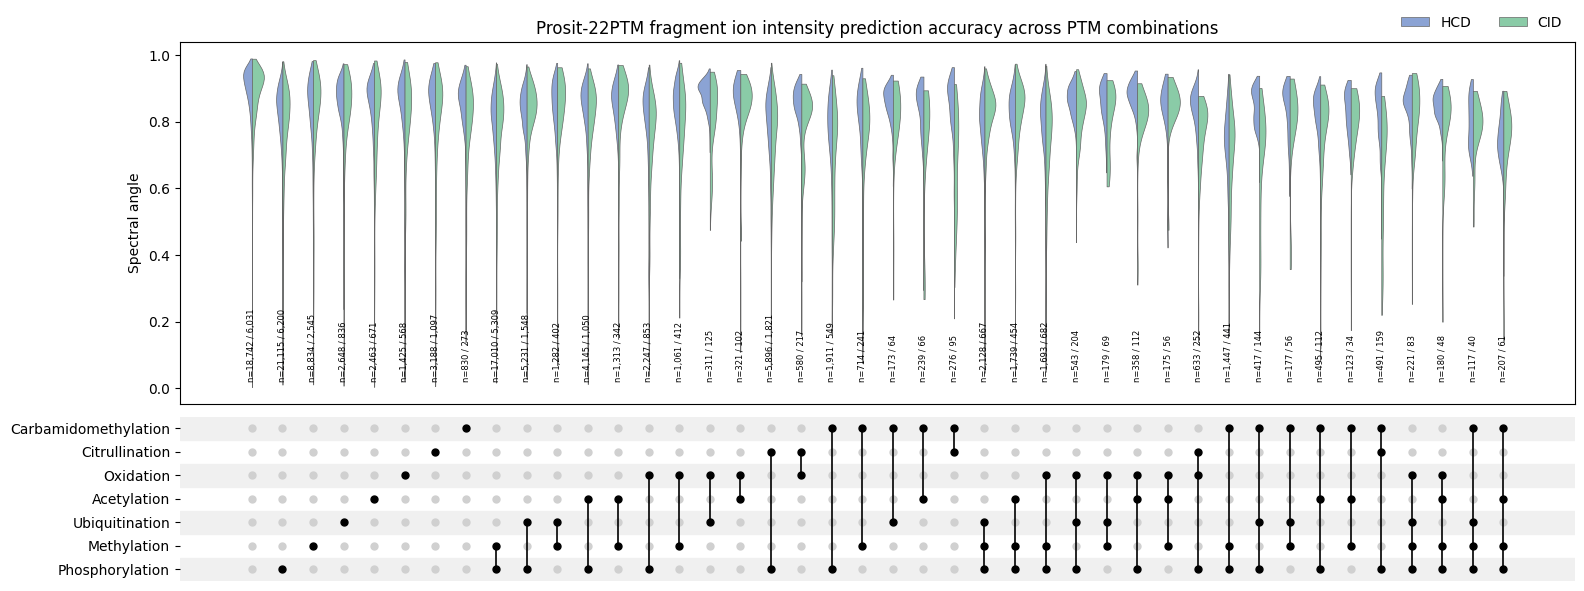

,column (left to right),modification_combination,Phosphorylation,Methylation,Ubiquitination,Acetylation,Citrullination,Oxidation,Carbamidomethylation,n_HCD_spectra_in_dataset,n_CID_spectra_in_dataset,n_HCD_spectra_with_Prosit-22PTM_prediction,median_spectral_angle_HCD (Prosit-22PTM),n_CID_spectra_with_Prosit-22PTM_prediction,median_spectral_angle_CID (Prosit-22PTM)
0,1,unmodified,False,False,False,False,False,False,False,18742,6031,18742,0.910720,6031,0.906845
1,2,Phospho,True,False,False,False,False,False,False,21115,6200,21115,0.840231,6200,0.810683
2,3,Methyl,False,True,False,False,False,False,False,8834,2545,8834,0.862754,2545,0.857441
3,4,Ubi,False,False,True,False,False,False,False,2648,836,2648,0.873820,836,0.859269
4,5,Acetyl,False,False,False,True,False,False,False,2463,671,2463,0.875055,671,0.846820
5,6,Oxidation,False,False,False,False,False,True,False,1425,568,1425,0.878248,568,0.834692
6,7,Citrullination,False,False,False,False,True,False,False,3188,1097,3188,0.879735,1097,0.852803
7,8,Carbamidomethyl,False,False,False,False,False,False,True,830,273,830,0.871005,273,0.824725
8,9,Phospho_Methyl,True,True,False,False,False,False,False,17010,5309,17010,0.817639,5309,0.802312
9,10,Phospho_Ubi,True,False,True,False,False,False,False,5231,1548,5231,0.841922,1548,0.843490


In [4]:
bn = table('Fig5b_n')
bd = pd.read_parquet(fetch('Wilhelm_SourceData_Fig5b.parquet'))
order = bn['modification_combination'].tolist()
bd['modification_combination'] = bd['modification_combination'].replace('', 'unmodified')
ROWS = ['Carbamidomethylation', 'Citrullination', 'Oxidation', 'Acetylation', 'Ubiquitination', 'Methylation', 'Phosphorylation']  # top to bottom
COL = {'HCD': '#7f9fe0', 'CID': '#7fd6a6'}

fig, (ax, axm) = plt.subplots(2, 1, figsize=(18, 7), sharex=True, gridspec_kw={'height_ratios': [2.2, 1], 'hspace': 0.05})
sns.violinplot(data=bd, x='modification_combination', y='spectral_angle', hue='fragmentation', order=order, cut=0,
               hue_order=['HCD', 'CID'], split=True, inner=None, palette=COL, linewidth=0.5, ax=ax)
for i, r in bn.iterrows():
    if r['n_HCD_spectra_with_Prosit-22PTM_prediction'] == 0 and r['n_CID_spectra_with_Prosit-22PTM_prediction'] == 0:
        ax.text(i, 0.6, 'NA', ha='center', va='center', fontsize=8, color='grey')
    ax.text(i, 0.02, 'n={:,} / {:,}'.format(r['n_HCD_spectra_in_dataset'], r['n_CID_spectra_in_dataset']),
            rotation=90, fontsize=6, ha='center', va='bottom')
ax.set_xlabel('')
ax.set_ylabel('Spectral angle')
ax.set_title('Prosit-22PTM fragment ion intensity prediction accuracy across PTM combinations')
ax.legend(title=None, loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False)
# upset matrix
for j, m in enumerate(ROWS):
    yy = len(ROWS) - 1 - j
    if j % 2 == 0:
        axm.axhspan(yy - 0.5, yy + 0.5, color='#f0f0f0', zorder=0)
    on = bn[m].astype(bool).values
    axm.scatter(np.arange(len(bn))[~on], [yy] * (~on).sum(), color='#d0d0d0', s=25, zorder=2)
    axm.scatter(np.arange(len(bn))[on], [yy] * on.sum(), color='k', s=25, zorder=3)
for i in range(len(bn)):
    ys = [len(ROWS) - 1 - j for j, m in enumerate(ROWS) if bool(bn.loc[i, m])]
    if len(ys) > 1:
        axm.plot([i, i], [min(ys), max(ys)], color='k', lw=1.2, zorder=2)
axm.set_yticks(range(len(ROWS)), ROWS[::-1])
axm.set_ylim(-0.5, len(ROWS) - 0.5)
axm.set_xticks([])
axm.set_xlabel('')
for s in axm.spines.values():
    s.set_visible(False)
save('Fig5b')
plt.show()
bn

## Panel c — spectral angle by number of different modifications (histone H3)

Spectral angle of each PSM (Prosit-22PTM rescoring of the histone data PXD024745, PSM q-value <= 0.01) by number of different modifications per peptide, split by N-terminal modification (seaborn `violinplot` defaults: Scott bandwidth, `cut=2`). n per violin half from `Wilhelm_SourceData_Fig5c_n.csv`.

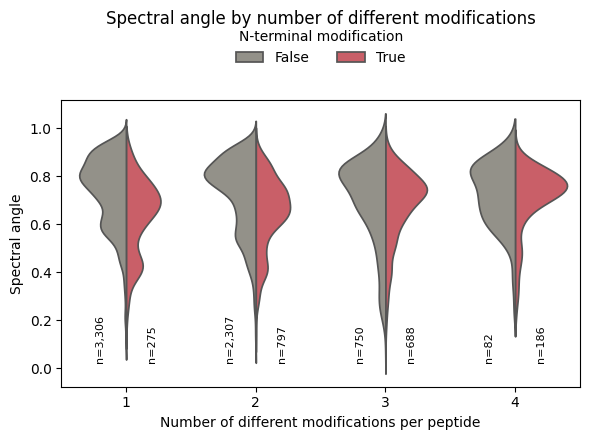

,n_different_modifications_per_peptide,N-terminal_modification,n_PSMs,median_spectral_angle
0,1,False,3306,0.766529
1,1,True,275,0.665754
2,2,False,2307,0.764947
3,2,True,797,0.665015
4,3,False,750,0.745985
5,3,True,688,0.719233
6,4,False,82,0.730560
7,4,True,186,0.748039


In [5]:
c = pd.read_parquet(fetch('Wilhelm_SourceData_Fig5c.parquet'))
cn = table('Fig5c_n')
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.violinplot(data=c, x='n_different_modifications_per_peptide', y='spectral_angle', hue='N-terminal_modification',
               hue_order=[False, True], split=True, inner=None, palette=['#959287', '#DA4E59'], ax=ax)
for i, r in cn.iterrows():
    xpos = r['n_different_modifications_per_peptide'] - 1 + (0.2 if r['N-terminal_modification'] else -0.2)
    ax.text(xpos, 0.02, f"n={r['n_PSMs']:,}", rotation=90, ha='center', va='bottom', fontsize=8)
ax.set_xlabel('Number of different modifications per peptide')
ax.set_ylabel('Spectral angle')
ax.set_title('Spectral angle by number of different modifications', pad=55)
ax.legend(title='N-terminal modification', frameon=False, ncol=2, loc='lower center', bbox_to_anchor=(0.5, 1.08))
plt.tight_layout()
save('Fig5c')
plt.show()
cn

## Panel d — PSMs identified with rescoring compared to MSFragger (histone H3)

PSMs common / gained / lost with Prosit-22PTM rescoring compared to MSFragger + Percolator (PSM q-value <= 0.01), matched by raw file and scan number; bar heights are fractions of the MSFragger PSMs (common + lost), labels are PSM counts.

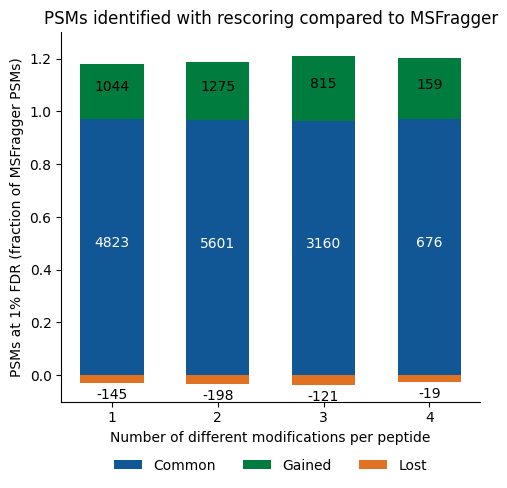

,n_different_modifications_per_peptide,n_common,n_gained,n_lost,common_fraction_of_MSFragger_PSMs,gained_fraction_of_MSFragger_PSMs,lost_fraction_of_MSFragger_PSMs
0,1,4823,1044,145,0.970813,0.210145,0.029187
1,2,5601,1275,198,0.965856,0.219865,0.034144
2,3,3160,815,121,0.963121,0.248400,0.036879
3,4,676,159,19,0.972662,0.228777,0.027338


In [6]:
d = table('Fig5d')
fig, ax = plt.subplots(figsize=(5, 5))
x = d['n_different_modifications_per_peptide']
com, gai, los = (d[f'{k}_fraction_of_MSFragger_PSMs'] for k in ('common', 'gained', 'lost'))
ax.bar(x, com, color='#115795', width=0.6, label='Common')
ax.bar(x, gai, bottom=com, color='#007D3E', width=0.6, label='Gained')
ax.bar(x, -los, color='#E17224', width=0.6, label='Lost')
for xi, cv, gv, lv, r in zip(x, com, gai, los, d.itertuples()):
    ax.text(xi, cv / 2, r.n_common, ha='center', color='white')
    ax.text(xi, cv + gv / 2, r.n_gained, ha='center', color='black')
    ax.text(xi, -lv - 0.06, f'-{r.n_lost}', ha='center', color='black')
ax.set_xticks(x)
ax.set_ylim(-0.1, 1.3)
ax.set_xlabel('Number of different modifications per peptide')
ax.set_ylabel('PSMs at 1% FDR (fraction of MSFragger PSMs)')
ax.set_title('PSMs identified with rescoring compared to MSFragger')
ax.legend(frameon=False, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
save('Fig5d')
plt.show()
d

## Panel e — histone H3 modification states

Histone H3 modification states per sample preparation (D3-Ac, PRO, PRO-PRO, PRO-PIC, Arg-C): quantified / identified / not identified; X marks states quantified in the study that generated the histone data set (columns `<sample> quantified_in_original_study`).

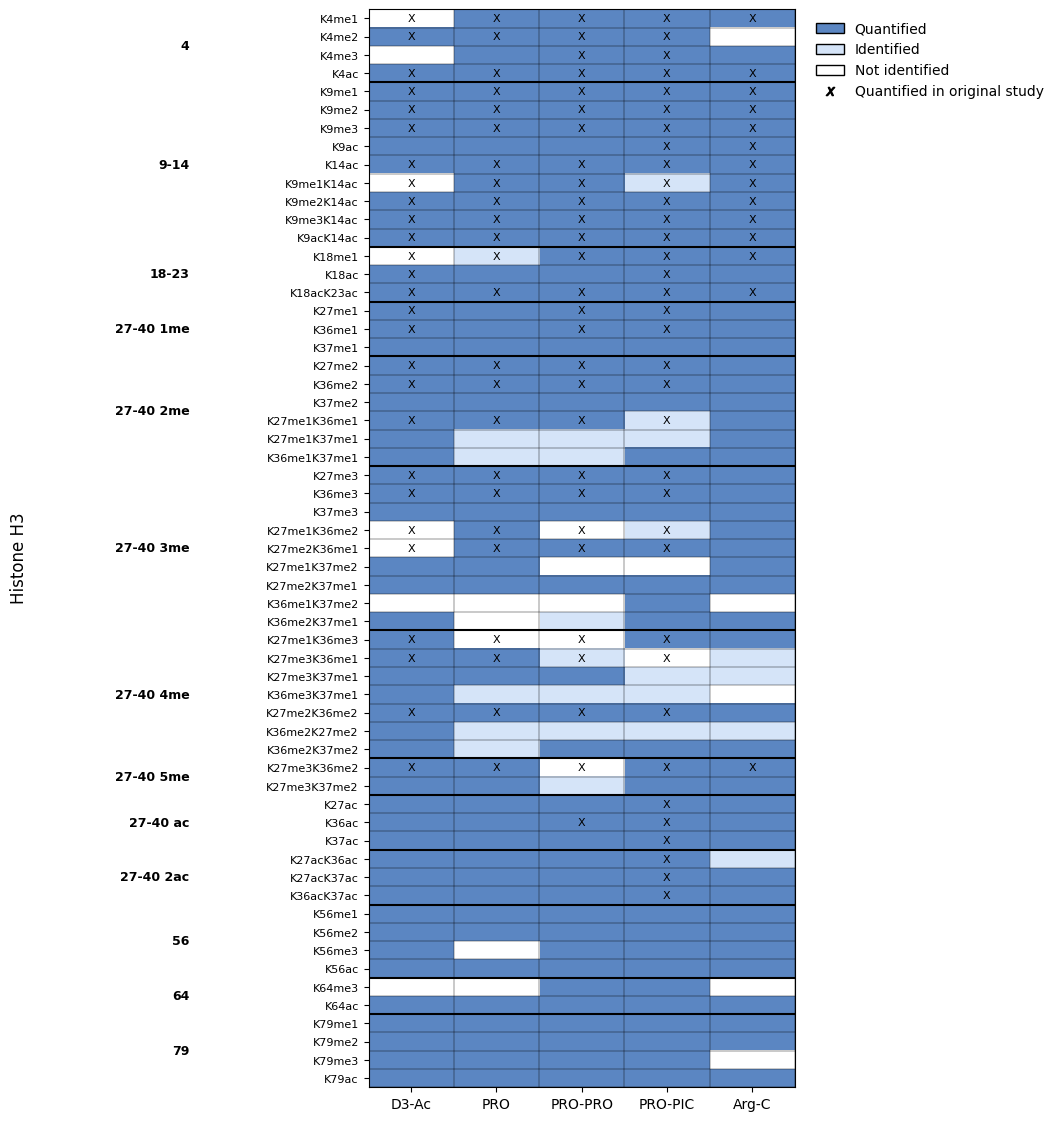

,residue_group (H3 residues),modified_peptide (H3 modification state),D3-Ac status,PRO status,PRO-PRO status,PRO-PIC status,Arg-C status,D3-Ac quantified_in_original_study,PRO quantified_in_original_study,PRO-PRO quantified_in_original_study,PRO-PIC quantified_in_original_study,Arg-C quantified_in_original_study
0,4,K4me1,Not identified,Quantified,Quantified,Quantified,Quantified,yes,yes,yes,yes,yes
1,4,K4me2,Quantified,Quantified,Quantified,Quantified,Not identified,yes,yes,yes,yes,no
2,4,K4me3,Not identified,Quantified,Quantified,Quantified,Quantified,no,no,yes,yes,no
3,4,K4ac,Quantified,Quantified,Quantified,Quantified,Quantified,yes,yes,yes,yes,yes
4,9-14,K9me1,Quantified,Quantified,Quantified,Quantified,Quantified,yes,yes,yes,yes,yes
5,9-14,K9me2,Quantified,Quantified,Quantified,Quantified,Quantified,yes,yes,yes,yes,yes
6,9-14,K9me3,Quantified,Quantified,Quantified,Quantified,Quantified,yes,yes,yes,yes,yes
7,9-14,K9ac,Quantified,Quantified,Quantified,Quantified,Quantified,no,no,no,yes,yes
8,9-14,K14ac,Quantified,Quantified,Quantified,Quantified,Quantified,yes,yes,yes,yes,yes
9,9-14,K9me1K14ac,Not identified,Quantified,Quantified,Identified,Quantified,yes,yes,yes,yes,yes


In [7]:
e = table('Fig5e')
SAMPLES = ['D3-Ac', 'PRO', 'PRO-PRO', 'PRO-PIC', 'Arg-C']
LEV = {'Not identified': 0, 'Identified': 1, 'Quantified': 2}
M = e[[f'{s} status' for s in SAMPLES]].apply(lambda s: s.map(LEV)).astype(int).values
X = (e[[f'{s} quantified_in_original_study' for s in SAMPLES]] == 'yes').values
cmap = ListedColormap(['#FFFFFF', '#D5E4F8', '#5B86C2'])
fig, ax = plt.subplots(figsize=(5.5, 14))
ax.imshow(M, cmap=cmap, norm=BoundaryNorm([-.5, .5, 1.5, 2.5], 3), aspect='auto')
for i, j in zip(*np.where(X)):
    ax.text(j, i, 'X', ha='center', va='center', fontsize=8)
ax.set_xticks(range(len(SAMPLES)), SAMPLES)
ax.set_yticks(range(len(e)), e['modified_peptide (H3 modification state)'], fontsize=8)
ax.set_xticks(np.arange(-.5, len(SAMPLES)), minor=True)
ax.set_yticks(np.arange(-.5, len(e)), minor=True)
ax.grid(which='minor', color='k', lw=0.3)
ax.tick_params(which='minor', length=0)
groups = e['residue_group (H3 residues)']
bounds = np.where(groups.values[1:] != groups.values[:-1])[0]
for b in bounds:
    ax.axhline(b + 0.5, color='k', lw=1.5)
starts = np.r_[0, bounds + 1]
ends = np.r_[bounds, len(e) - 1]
for s0, s1 in zip(starts, ends):
    ax.text(-2.6, (s0 + s1) / 2, groups[s0], ha='right', va='center', fontsize=9, fontweight='bold',
            transform=ax.transData, clip_on=False)
ax.text(-4.6, len(e) / 2, 'Histone H3', rotation=90, ha='center', va='center', fontsize=12, clip_on=False)
ax.legend([Patch(fc=c, ec='k') for c in ['#5B86C2', '#D5E4F8', '#FFFFFF']] + [plt.Line2D([], [], ls='', marker='$X$', color='k')],
          ['Quantified', 'Identified', 'Not identified', 'Quantified in original study'],
          loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
save('Fig5e')
plt.show()
e